# Recomendação de culturas agrícolas

A ideia do projeto é usar informações do solo e do clima para classificar qual cultura é mais compatível com os valores informados.

O dataset usa sete variáveis de entrada:

- N: nitrogênio
- P: fósforo
- K: potássio
- temperature: temperatura
- humidity: umidade
- ph: pH do solo
- rainfall: precipitação

A coluna `label` é a cultura que será prevista.


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
from sklearn.pipeline import make_pipeline
import joblib


## Carregando os dados


In [5]:
dados = pd.read_csv("Crop_recommendation.csv")
dados.head()


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## Conferência inicial


In [6]:
print("Quantidade de linhas e colunas:", dados.shape)
print()
print("Colunas:")
print(dados.columns.tolist())
print()
print("Tipos dos dados:")
print(dados.dtypes)


Quantidade de linhas e colunas: (2200, 8)

Colunas:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

Tipos dos dados:
N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label              str
dtype: object


In [7]:
print("Valores ausentes por coluna:")
print(dados.isnull().sum())

print()
print("Linhas duplicadas:", dados.duplicated().sum())


Valores ausentes por coluna:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Linhas duplicadas: 0


In [8]:
dados.describe()


,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


## Distribuição das culturas


label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


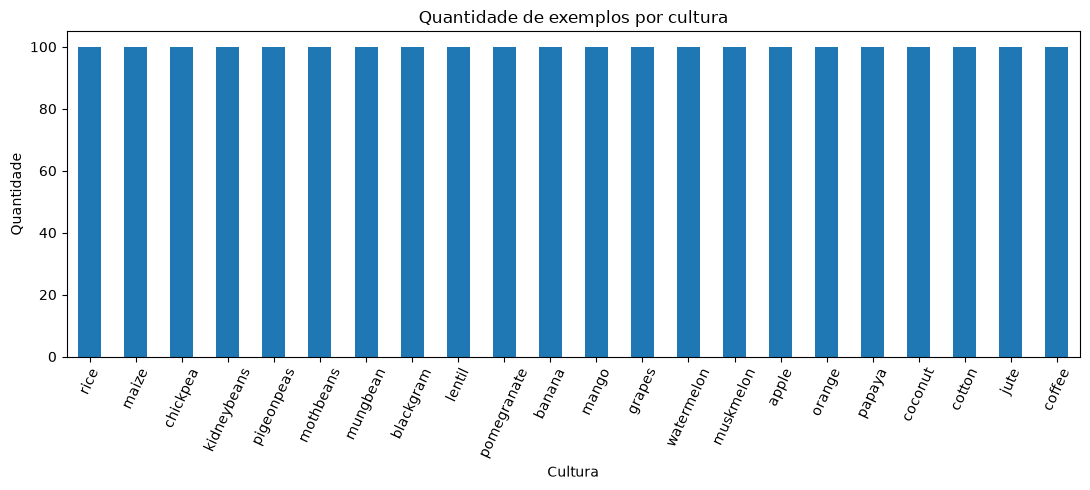

In [9]:
contagem_culturas = dados["label"].value_counts()

print(contagem_culturas)

plt.figure(figsize=(11, 5))
contagem_culturas.plot(kind="bar")
plt.title("Quantidade de exemplos por cultura")
plt.xlabel("Cultura")
plt.ylabel("Quantidade")
plt.xticks(rotation=65)
plt.tight_layout()
plt.show()


Esse gráfico serve para verificar se alguma cultura aparece muito mais do que as outras.
Isso é importante porque classes muito desbalanceadas podem tendenciar os resultados e afetar a tomada de decisão do modelo.


## Distribuição das variáveis


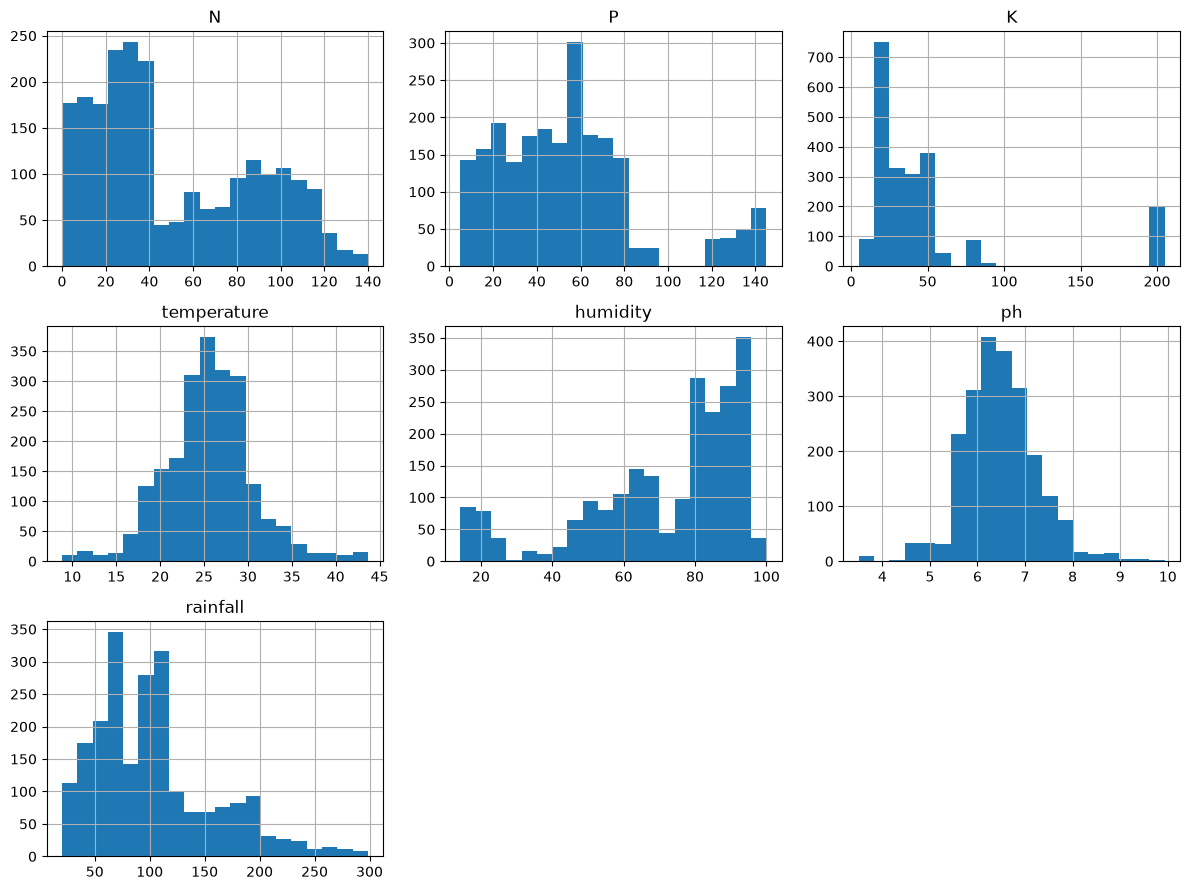

In [10]:
colunas_numericas = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]

dados[colunas_numericas].hist(figsize=(12, 9), bins=20)
plt.tight_layout()
plt.show()


## Correlação entre as variáveis


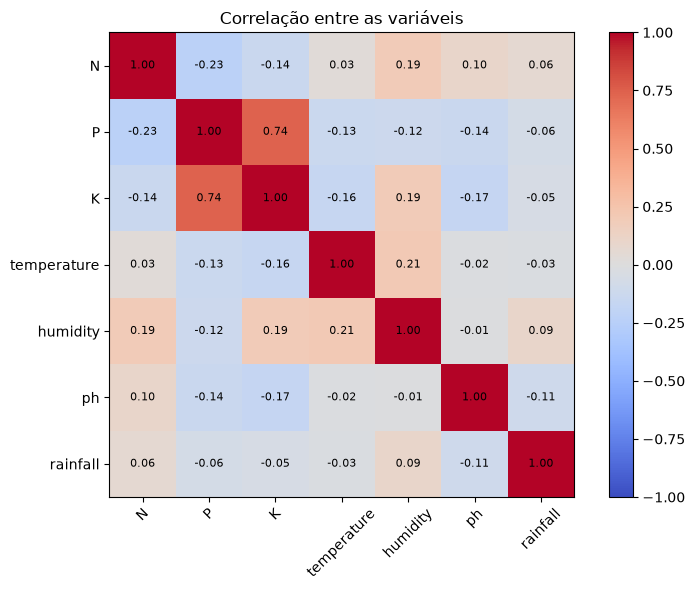

In [11]:
correlacao = dados[colunas_numericas].corr()

plt.figure(figsize=(8, 6))
plt.imshow(correlacao, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar()

plt.xticks(range(len(colunas_numericas)), colunas_numericas, rotation=45)
plt.yticks(range(len(colunas_numericas)), colunas_numericas)

for i in range(len(colunas_numericas)):
    for j in range(len(colunas_numericas)):
        plt.text(j, i, f"{correlacao.iloc[i, j]:.2f}",
                 ha="center", va="center", fontsize=8)

plt.title("Correlação entre as variáveis")
plt.tight_layout()
plt.show()


## Separação entre treino e teste

Foi usada divisão estratificada para manter a proporção das culturas nos dois conjuntos.


In [12]:
X = dados[colunas_numericas]
y = dados["label"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Treino:", X_treino.shape)
print("Teste:", X_teste.shape)


Treino: (1760, 7)
Teste: (440, 7)


## Modelo 1 - Regressão Logística

A Regressão Logística usa a escala das variáveis durante o ajuste. Por isso ela foi colocada junto com `StandardScaler` em um pipeline.

O `StandardScaler` é ajustado somente com os dados de treino.


In [13]:
modelo_logistico = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=3000, random_state=42)
)

modelo_logistico.fit(X_treino, y_treino)

pred_logistica = modelo_logistico.predict(X_teste)


## Modelo 2 - Árvore de Decisão


In [14]:
modelo_arvore = DecisionTreeClassifier(random_state=42)

modelo_arvore.fit(X_treino, y_treino)

pred_arvore = modelo_arvore.predict(X_teste)


## Comparação dos modelos

Como existem várias culturas, além da acurácia serão usadas precisão, recall e F1 com média macro.
Assim, cada classe tem o mesmo peso na avaliação.


In [15]:
resultados = pd.DataFrame([
    {
        "Modelo": "Regressão Logística",
        "Acurácia": accuracy_score(y_teste, pred_logistica),
        "Precisão macro": precision_score(y_teste, pred_logistica, average="macro", zero_division=0),
        "Recall macro": recall_score(y_teste, pred_logistica, average="macro", zero_division=0),
        "F1 macro": f1_score(y_teste, pred_logistica, average="macro", zero_division=0)
    },
    {
        "Modelo": "Árvore de Decisão",
        "Acurácia": accuracy_score(y_teste, pred_arvore),
        "Precisão macro": precision_score(y_teste, pred_arvore, average="macro", zero_division=0),
        "Recall macro": recall_score(y_teste, pred_arvore, average="macro", zero_division=0),
        "F1 macro": f1_score(y_teste, pred_arvore, average="macro", zero_division=0)
    }
])

resultados


,Modelo,Acurácia,Precisão macro,Recall macro,F1 macro
0,Regressão Logística,0.972727,0.974022,0.972727,0.972464
1,Árvore de Decisão,0.979545,0.980598,0.979545,0.979423


## Relatório detalhado - Regressão Logística


In [16]:
print(classification_report(y_teste, pred_logistica))


              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       0.95      1.00      0.98        20
    chickpea       1.00      1.00      1.00        20
     coconut       0.95      1.00      0.98        20
      coffee       1.00      1.00      1.00        20
      cotton       0.95      1.00      0.98        20
      grapes       1.00      1.00      1.00        20
        jute       0.83      1.00      0.91        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.94      0.85      0.89        20
       maize       1.00      0.95      0.97        20
       mango       0.95      1.00      0.98        20
   mothbeans       0.90      0.90      0.90        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      0.95      0.97        20
      papaya       1.00    

## Relatório detalhado - Árvore de Decisão


In [17]:
print(classification_report(y_teste, pred_arvore))


              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.80      0.89        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      0.95      0.95        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.86      0.90      0.88        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.86      0.95      0.90        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

## Matrizes de confusão


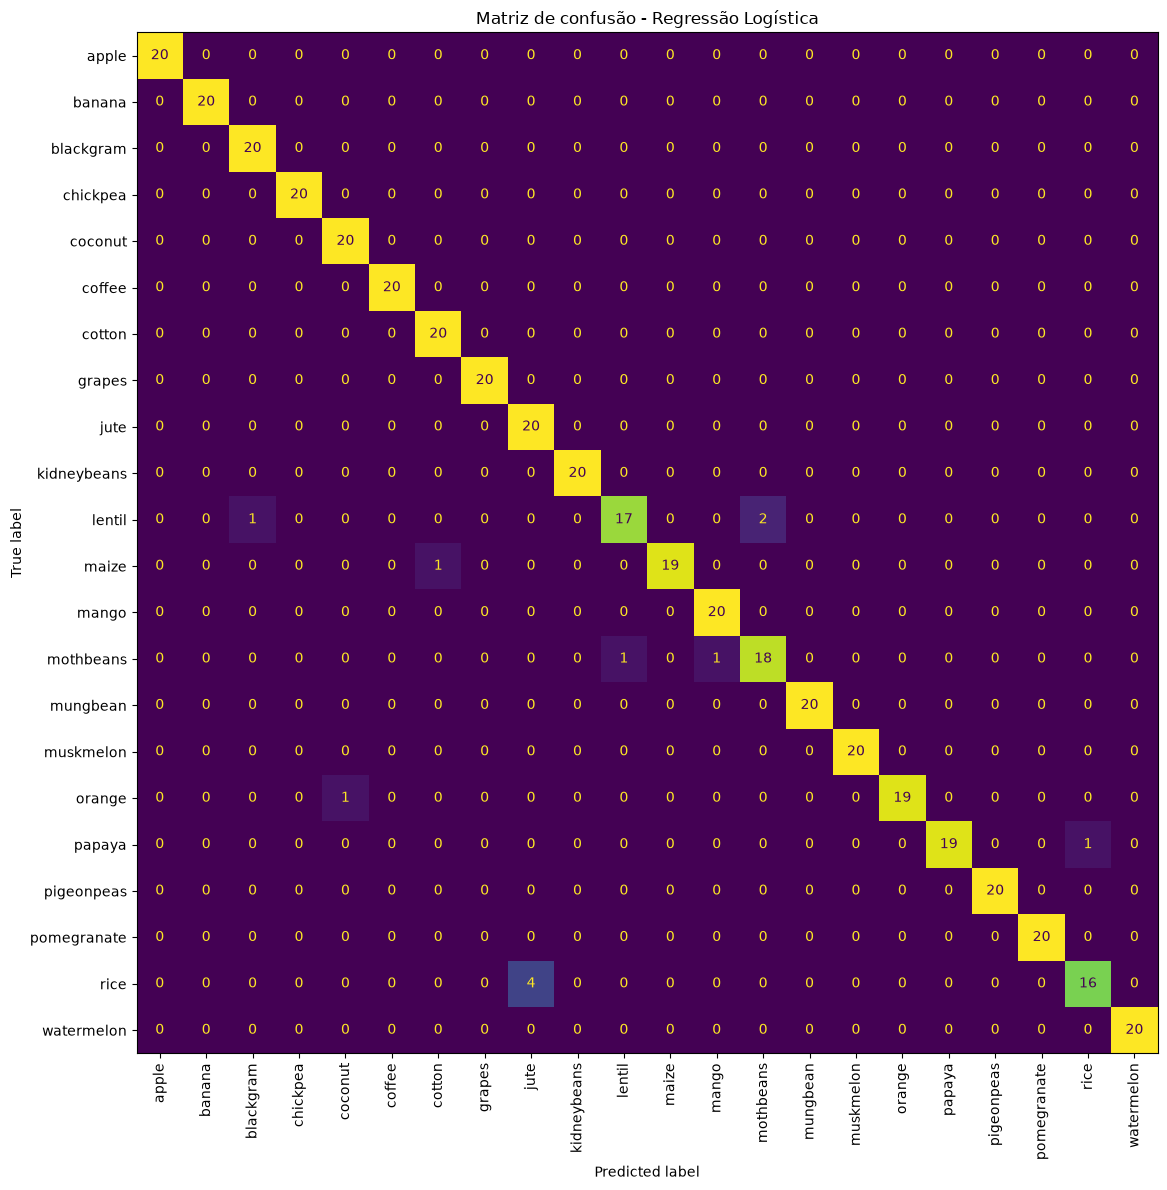

In [18]:
fig, ax = plt.subplots(figsize=(12, 12))

ConfusionMatrixDisplay.from_predictions(
    y_teste,
    pred_logistica,
    xticks_rotation=90,
    ax=ax,
    colorbar=False
)

plt.title("Matriz de confusão - Regressão Logística")
plt.tight_layout()
plt.show()


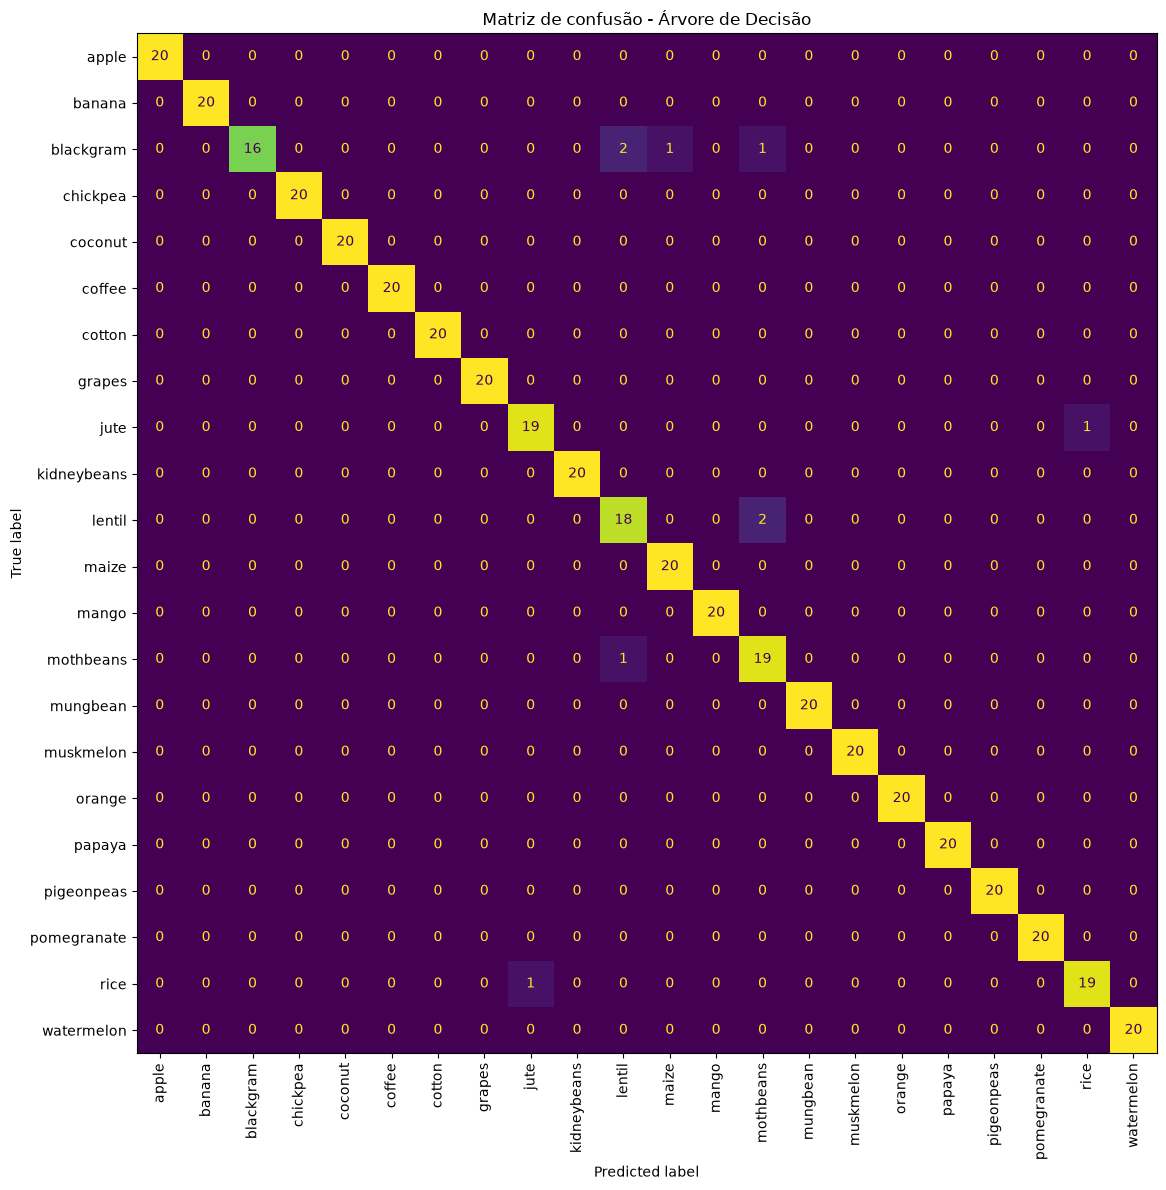

In [19]:
fig, ax = plt.subplots(figsize=(12, 12))

ConfusionMatrixDisplay.from_predictions(
    y_teste,
    pred_arvore,
    xticks_rotation=90,
    ax=ax,
    colorbar=False
)

plt.title("Matriz de confusão - Árvore de Decisão")
plt.tight_layout()
plt.show()


## Salvando o modelo escolhido

In [20]:
modelo_final = modelo_arvore

joblib.dump(modelo_final, "crop_model.joblib")

print("Modelo salvo em crop_model.joblib")


Modelo salvo em crop_model.joblib


## Testando uma nova entrada


In [21]:
nova_entrada = pd.DataFrame([{
    "N": 90,
    "P": 42,
    "K": 43,
    "temperature": 20.88,
    "humidity": 82.0,
    "ph": 6.5,
    "rainfall": 202.94
}])

previsao = modelo_final.predict(nova_entrada)

print("Cultura prevista:", previsao[0])


Cultura prevista: rice


## Limitações

O modelo considera somente as variáveis presentes no dataset.
Na prática, uma decisão agrícola também pode depender de fatores que não aparecem aqui, como tipo de solo, altitude, disponibilidade de irrigação, época de plantio, ocorrência de pragas e condições econômicas.

Por isso, o resultado deve ser tratado como uma previsão acadêmica baseada no dataset, e não como recomendação agronômica profissional. No final da execução da previsão um aviso é gerado, alertando para esse detalhe.